# Three-way comparison: MATLAB, BAYSPLINEpy, and `brews/baysplinepy`

Runs the BAYSPLINE examples through every available implementation and compares the answers.

| | What it is |
|---|---|
| **MATLAB** | `UK_predict.m`, `UK_forward.m`, `checkSeasonality.m` run unmodified, their output saved to `docs/BAYSPLINEpy/audit/original_matlab.mat` by `audit/verify_original.m`. The reference. |
| **BAYSPLINEpy** | this port (`import baysplinepy`), on every CPU |
| **brews/baysplinepy** | S. B. Malevich's port (`import bayspline`), `pip install baysplinepy` — optional; the notebook says so and carries on if it is missing |

The examples:

1. `DemoScript.m` — UK'37 from the Gulf of Aden (`DemoUKData.csv`), `pstd = 5`. High UK'37, where
   the calibration flattens and the prior matters most.
2. `uk = [0.4 0.5 0.6]`, `pstd = 7.5` — the case in `brews/baysplinepy`'s own tests.
3. `UK_forward.m` over −5…35 °C, and `checkSeasonality.m` on edge cases.

**To regenerate the MATLAB reference** (from the repository root; both work):

```bash
matlab -batch "addpath('docs/BAYSPLINEpy/audit'); verify_original"
octave --no-gui --quiet --eval "pkg load statistics; addpath('docs/BAYSPLINEpy/audit'); verify_original"
```

The committed reference was made with **GNU Octave**, which lacks the Curve Fitting Toolbox; there
`verify_original.m` adds `audit/octave_shims/` (`augknt`, `spmak`, `fnxtr`, `fnval`) written from
MATLAB's documentation. Every other line executed is the original `.m` source. The spline itself is
also checked against an independent re-implementation (Brewster's) below, so the shims are not the
only witness. Re-running under MATLAB removes the caveat.

In [1]:
import inspect, os, sys, time, warnings
from pathlib import Path

import numpy as np
import scipy.io as sio
import matplotlib as mpl
import matplotlib.pyplot as plt

import baysplinepy as ours

# brews/baysplinepy is optional. Both packages coexist because this one imports as
# `baysplinepy` and his as `bayspline` -- that is why the import name was chosen.
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        import bayspline as brews
        import bayspline.predict as brews_predict
    HAVE_BREWS = True
except ImportError:
    brews, brews_predict, HAVE_BREWS = None, None, False
warnings.filterwarnings("ignore", category=DeprecationWarning, module="bayspline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().resolve().parents] if (p / "UK_predict.m").is_file())
REF = ROOT / "docs" / "BAYSPLINEpy" / "audit" / "original_matlab.mat"
HAVE_REF = REF.is_file()
ref = sio.loadmat(str(REF), squeeze_me=True, struct_as_record=False) if HAVE_REF else {}

SEED = 0
print(f"BAYSPLINEpy        {ours.__version__}   CPUs available: {ours.available_cpus()}")
print(f"brews/baysplinepy  {'installed' if HAVE_BREWS else 'NOT INSTALLED - pip install baysplinepy'}")
print(f"MATLAB reference   {'found: ' + str(REF.relative_to(ROOT)) if HAVE_REF else 'MISSING - run verify_original.m'}")
if HAVE_REF:
    pv = ref["provenance"]
    print(f"                   made by {pv.engine} on {pv.when}; shims: {pv.shims}")
print(f"numpy {np.__version__}")

BAYSPLINEpy        0.1.0.dev0   CPUs available: 4
brews/baysplinepy  installed
MATLAB reference   found: docs/BAYSPLINEpy/audit/original_matlab.mat
                   made by Octave 8.4.0 on 2026-10-19 23:57:38; shims: audit/octave_shims (augknt, spmak, fnxtr, fnval, ksdensity)
numpy 2.5.4


In [2]:
# One fixed colour per implementation, assigned in a fixed order and never cycled; the same
# three as the BAYSPAR comparison. "brews, one-line fix" is the same package, so it keeps
# brews' colour and is told apart by a dashed line rather than a fourth hue.
COLORS = {"MATLAB": "#2a78d6", "BAYSPLINEpy": "#eb6834", "brews/baysplinepy": "#1baf7a"}
INK, MUTED, GRID = "#1a1a19", "#5c5b55", "#e2e1dc"

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 120, "font.size": 9,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False, "figure.facecolor": "white", "axes.facecolor": "white",
})

LEVELS = [2.5, 50, 97.5]          # what UK_predict.m reports as output.SST

def matlab_levels(pool):
    '''UK_predict.m's convention: sort, index round([.025 .5 .975]*n). Any ensemble.'''
    n = pool.shape[1]
    k = np.floor(np.array(LEVELS) / 100 * n + 0.5).astype(int) - 1
    return np.partition(pool, k, axis=1)[:, k]

def summarise(name, sst, reference=None):
    row = {"implementation": name,
           "p2.5 (median over points)": np.median(sst[:, 0]),
           "p50": np.median(sst[:, 1]),
           "p97.5": np.median(sst[:, 2]),
           "95% width": np.median(sst[:, 2] - sst[:, 0])}
    if reference is not None:
        d = sst - reference
        row["mean diff p50 vs MATLAB"] = d[:, 1].mean()
        row["mean diff p97.5"] = d[:, 2].mean()
    return row

def show(rows):
    keys = list(dict.fromkeys(k for r in rows for k in r))
    fmt = lambda k, v: (f"{v:+.3f}" if "diff" in k else f"{v:.3f}") if isinstance(v, float) else str(v)
    cells = [[fmt(k, r.get(k, "")) for k in keys] for r in rows]
    widths = [max(len(k), *(len(c[i]) for c in cells)) for i, k in enumerate(keys)]
    print("  ".join(k.ljust(w) for k, w in zip(keys, widths)))
    for c in cells:
        print("  ".join(v.ljust(w) for v, w in zip(c, widths)))

## 1. `DemoScript.m` — Gulf of Aden, `pstd = 5`

`brews/baysplinepy` as shipped, and the same code with **one line changed** (explained in §2), are
both run. Its `Prediction.percentile()` calls `np.percentile(interpolation=...)`, which NumPy 2.0
removed, so the percentiles below are computed from its ensemble with MATLAB's own convention —
the same rule applied to every implementation.

In [3]:
demo = ours.load_demo_data()
uk, age = demo["uk37"], demo["ageBP"]
PSTD = 5.0

matlab_sst = np.atleast_2d(ref["demo"].SST) if HAVE_REF else None
if HAVE_REF:
    np.testing.assert_array_equal(np.atleast_1d(ref["demo_input"].uk), uk)

t0 = time.perf_counter()
out = ours.uk_predict(uk, PSTD, seed=SEED, save_samples=True)
print(f"BAYSPLINEpy: {time.perf_counter() - t0:.2f} s on {out.metadata['n_jobs']} workers")

rows = []
if HAVE_REF:
    rows.append(summarise("MATLAB", matlab_sst))
rows.append(summarise("BAYSPLINEpy", out.sst, matlab_sst))

if HAVE_BREWS:
    # the one-line fix, applied to his source rather than re-typed, so nothing else changes
    src = inspect.getsource(brews_predict.predict_sst)
    assert "sample_now = initial_sst\n" in src
    ns = dict(vars(brews_predict))
    exec(src.replace("sample_now = initial_sst\n", "sample_now = initial_sst.copy()\n")
            .replace("def predict_sst(", "def predict_sst_fixed("), ns)
    brews_fixed = ns["predict_sst_fixed"]

    np.random.seed(SEED)
    t0 = time.perf_counter()
    b_out = brews.predict_sst(uk, PSTD, progressbar=False)
    t_brews = time.perf_counter() - t0
    np.random.seed(SEED)
    bf_out = brews_fixed(uk, PSTD, progressbar=False)
    brews_sst, brews_fixed_sst = matlab_levels(b_out.ensemble), matlab_levels(bf_out.ensemble)
    rows.append(summarise("brews/baysplinepy", brews_sst, matlab_sst))
    rows.append(summarise("brews, one-line fix", brews_fixed_sst, matlab_sst))
show(rows)

print()
print("R-hat     ", f"MATLAB {float(ref['demo'].rhat):.3f} | " if HAVE_REF else "",
      f"BAYSPLINEpy {out.rhat:.3f}",
      f"| brews {float(np.ravel(b_out.rhat)[0]):.3f} | brews fixed {float(np.ravel(bf_out.rhat)[0]):.3f}" if HAVE_BREWS else "")
print("acceptance", f"MATLAB {float(ref['demo'].accepts):.3f} | " if HAVE_REF else "",
      f"BAYSPLINEpy {out.accepts:.3f}",
      f"| brews {b_out.acceptance:.3f} | brews fixed {bf_out.acceptance:.3f}" if HAVE_BREWS else "")
if HAVE_REF:
    print(f"prior mean identical to MATLAB: {np.array_equal(out.prior_mean, np.atleast_1d(ref['demo'].prior_mean))}; "
          f"jump width {out.jump_dist:.4f} vs MATLAB {float(ref['demo'].jump_dist):.4f}")

BAYSPLINEpy: 1.54 s on 4 workers


implementation       p2.5 (median over points)  p50     p97.5   95% width  mean diff p50 vs MATLAB  mean diff p97.5
MATLAB               23.983                     27.726  33.624  9.644                                              
BAYSPLINEpy          23.979                     27.723  33.765  9.691      +0.000                   +0.007         
brews/baysplinepy    24.111                     28.158  37.066  12.980     +0.486                   +3.406         
brews, one-line fix  24.018                     27.728  33.745  9.743      +0.003                   +0.010         

R-hat      MATLAB 1.017 |  BAYSPLINEpy 1.017 | brews 1.160 | brews fixed 1.017
acceptance MATLAB 0.401 |  BAYSPLINEpy 0.401 | brews 0.439 | brews fixed 0.401
prior mean identical to MATLAB: True; jump width 6.3509 vs MATLAB 6.3509


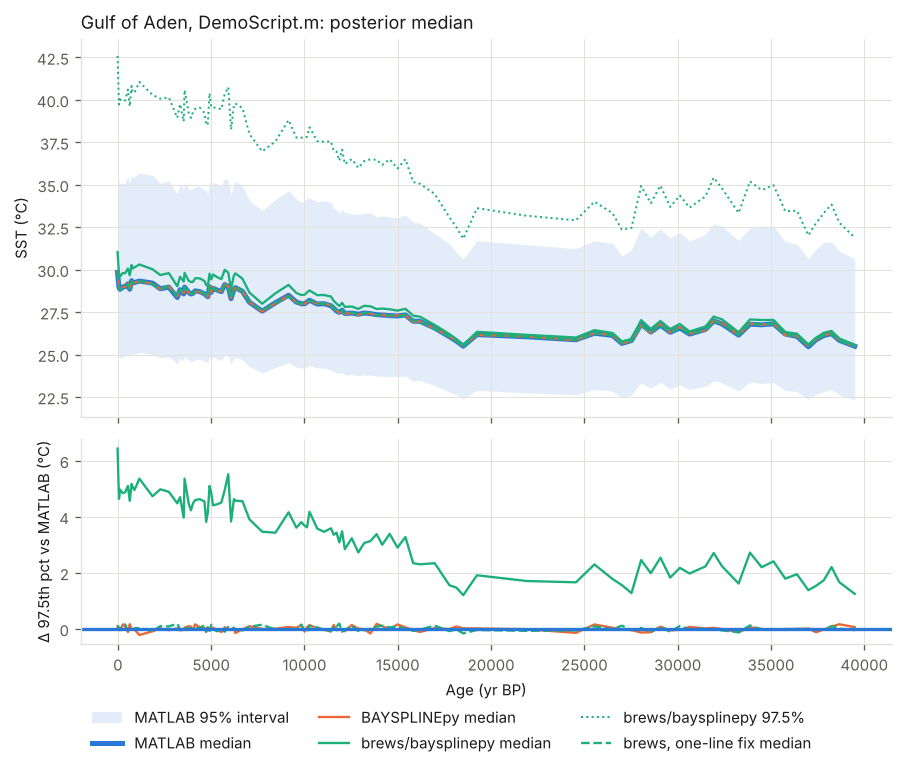

In [4]:
o = np.argsort(age)
fig, (ax, axd) = plt.subplots(2, 1, figsize=(7.6, 6.0), sharex=True,
                              gridspec_kw={"height_ratios": [2.4, 1.3]})

ref_sst = matlab_sst if HAVE_REF else out.sst
ref_name = "MATLAB" if HAVE_REF else "BAYSPLINEpy"
ax.fill_between(age[o], ref_sst[o, 0], ref_sst[o, 2], color=COLORS[ref_name], alpha=0.13,
                linewidth=0, label=f"{ref_name} 95% interval")
series = [("MATLAB", matlab_sst, "-")] if HAVE_REF else []
series.append(("BAYSPLINEpy", out.sst, "-"))
if HAVE_BREWS:
    series += [("brews/baysplinepy", brews_sst, "-"), ("brews, one-line fix", brews_fixed_sst, "--")]
color_of = lambda n: COLORS.get(n, COLORS["brews/baysplinepy"])
for name, s, ls in series:
    lw = 3 if name == "MATLAB" else 1.4
    ax.plot(age[o], s[o, 1], ls=ls, lw=lw, color=color_of(name), label=f"{name} median",
            zorder=2 if name == "MATLAB" else 3)
    if name == "brews/baysplinepy":
        ax.plot(age[o], s[o, 2], ls=":", lw=1.2, color=color_of(name), label="brews/baysplinepy 97.5%")
ax.set_ylabel("SST (°C)")
ax.set_title("Gulf of Aden, DemoScript.m: posterior median", loc="left")

# lower panel: the upper bound, where the difference is largest
for name, s, ls in series:
    if HAVE_REF and name == "MATLAB":
        continue
    axd.plot(age[o], s[o, 2] - ref_sst[o, 2], ls=ls, lw=1.4, color=color_of(name))
axd.axhline(0, color=COLORS[ref_name], lw=2)
axd.set_ylabel(f"Δ 97.5th pct vs {ref_name} (°C)")
axd.set_xlabel("Age (yr BP)")
h, l = ax.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout()
plt.show()

## 2. Where `brews/baysplinepy`'s difference comes from

In his `predict_sst`:

```python
prior_mean = pmean_out * np.ones(n_uk)
initial_sst = prior_mean
...
sample_now = initial_sst          # the same array object as prior_mean
...
sample_now[b] = proposal[b]       # so this also moves the prior mean
```

Every accepted step overwrites the prior mean with the current state, so the prior follows the chain
instead of staying at the Prahl value; and because `initial_sst` is never reset, each of the 500
chains starts where the previous one ended. MATLAB has value semantics — `s_now = samps(:,1)` is a
copy — so the reference never had this. The fix is `initial_sst.copy()`, and the table above shows
that one change brings his port into agreement.

Two other things differ and are separable: his port loads an **earlier posterior file**
(`bayes_posterior.mat`, 1500 draws, thinned 1:3) where MATLAB loads `bayes_posterior_v2.mat` (1000,
thinned 1:2). Running *this* sampler on his file isolates that effect:

In [5]:
if HAVE_BREWS:
    from bayspline.modelparams import get_draws
    d = get_draws()
    # his draws, laid out so that this sampler's 1:2 thinning picks exactly his 1:3 subset
    v1 = ours.Posterior(bdraws=np.repeat(d["b_draws_final"][::3], 2, axis=0),
                        tau2=np.repeat(d["tau2_draws_final"].ravel()[::3], 2),
                        knots=d["knots"].ravel(), source="brews bayes_posterior.mat")
    on_v1 = ours.uk_predict(uk, PSTD, bayes=v1, seed=SEED)
    reseed = ours.uk_predict(uk, PSTD, seed=SEED + 1)
    def eff(a, b):
        d_ = a - b
        return f"p50 {d_[:,1].mean():+.3f} °C, p97.5 {d_[:,2].mean():+.3f} °C (mean over points)"
    print("effect on BAYSPLINEpy's output of ...")
    print(f"  the posterior file (his v1 instead of v2)  {eff(on_v1.sst, out.sst)}")
    print(f"  the prior aliasing (his, as shipped vs fixed)  {eff(brews_sst, brews_fixed_sst)}")
    print(f"  reseeding the same implementation           {eff(reseed.sst, out.sst)}")
else:
    print("brews/baysplinepy not installed - skipped")

effect on BAYSPLINEpy's output of ...
  the posterior file (his v1 instead of v2)  p50 +0.001 °C, p97.5 +0.005 °C (mean over points)
  the prior aliasing (his, as shipped vs fixed)  p50 +0.483 °C, p97.5 +3.396 °C (mean over points)
  reseeding the same implementation           p50 +0.000 °C, p97.5 +0.002 °C (mean over points)


## 3. Low UK'37 — `brews/baysplinepy`'s own test case

`uk = [0.4 0.5 0.6]`, `pstd = 7.5`. Here the likelihood is steep and dominates the prior, so the
aliasing has almost nothing to act on: all implementations should agree within noise.

In [6]:
uk_low, pstd_low = np.array([0.4, 0.5, 0.6]), 7.5
rows_low = []
m_low = np.atleast_2d(ref["low"].SST) if HAVE_REF else None
if HAVE_REF:
    rows_low.append(summarise("MATLAB", m_low))
low = ours.uk_predict(uk_low, pstd_low, seed=SEED)
rows_low.append(summarise("BAYSPLINEpy", low.sst, m_low))
if HAVE_BREWS:
    np.random.seed(SEED)
    rows_low.append(summarise("brews/baysplinepy", matlab_levels(brews.predict_sst(uk_low, pstd_low, progressbar=False).ensemble), m_low))
show(rows_low)
print()
print("per point, 2.5 / 50 / 97.5 (°C):")
if HAVE_REF:
    print("  MATLAB     ", np.round(m_low, 2).tolist())
print("  BAYSPLINEpy", np.round(low.sst, 2).tolist())

implementation     p2.5 (median over points)  p50     p97.5   95% width  mean diff p50 vs MATLAB  mean diff p97.5
MATLAB             10.394                     13.158  15.954  5.560                                              
BAYSPLINEpy        10.401                     13.162  15.928  5.556      +0.010                   -0.000         
brews/baysplinepy  10.397                     13.165  15.951  5.555      -0.011                   -0.005         

per point, 2.5 / 50 / 97.5 (°C):
  MATLAB      [[7.46, 10.21, 13.0], [10.39, 13.16, 15.95], [13.37, 16.14, 18.94]]
  BAYSPLINEpy [[7.46, 10.23, 13.01], [10.4, 13.16, 15.93], [13.35, 16.15, 18.95]]


## 4. The sampler across seeds, against the reference

One MATLAB run is one draw of Monte-Carlo noise. To ask whether the port is *biased* rather than
merely different, run it under several seeds and see where MATLAB's run falls in that spread.

run-to-run sd of each percentile, pooled over points (°C): 0.024, 0.019, 0.058
MATLAB vs mean of 8 BAYSPLINEpy runs, z-scores over 291 cells: mean -0.04, sd 0.97, max |z| 2.86
(an unbiased port gives mean ~0 and sd ~1)


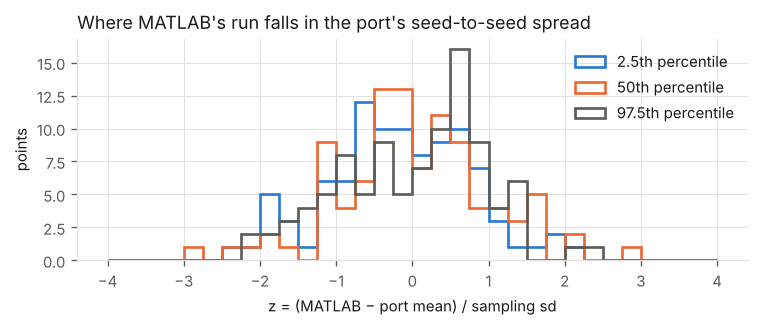

In [7]:
K = 8
runs = [ours.uk_predict(uk, PSTD, seed=s) for s in range(K)]
stack = np.stack([r.sst for r in runs])                 # (K, N, 3)
mean, sd = stack.mean(0), np.sqrt(stack.var(0, ddof=1).mean(0))   # sd pooled over points
print(f"run-to-run sd of each percentile, pooled over points (°C): "
      f"{', '.join(f'{v:.3f}' for v in sd)}")
if HAVE_REF:
    z = (matlab_sst - mean) / (sd * np.sqrt(1 + 1 / K))
    print(f"MATLAB vs mean of {K} BAYSPLINEpy runs, z-scores over {z.size} cells: "
          f"mean {z.mean():+.2f}, sd {z.std():.2f}, max |z| {np.abs(z).max():.2f}")
    print("(an unbiased port gives mean ~0 and sd ~1)")
    fig, ax = plt.subplots(figsize=(6.4, 2.8))
    for j, lab in enumerate(["2.5th", "50th", "97.5th"]):
        ax.hist(z[:, j], bins=np.linspace(-4, 4, 33), histtype="step", lw=1.6,
                color=[COLORS["MATLAB"], COLORS["BAYSPLINEpy"], MUTED][j], label=f"{lab} percentile")
    ax.set_xlabel("z = (MATLAB − port mean) / sampling sd")
    ax.set_ylabel("points")
    ax.set_title("Where MATLAB's run falls in the port's seed-to-seed spread", loc="left")
    ax.legend()
    fig.tight_layout(); plt.show()

## 5. `output.ens` — four chains, not five hundred

`output.ens = MH_c(:, 1:125:end)`. `MH_c` is built with a column-major `reshape`, so its column `c`
is chain `c mod 500`; every 125th column is therefore chains 1, 126, 251 and 376 only. The 1000
ensemble members come from **four** of the 500 posterior spline draws. `output.SST` uses all 125,000
samples and is unaffected — but anyone who takes `output.ens` as "the posterior ensemble" (as
`DemoScript.m` suggests, exporting it to CSV) gets a version that under-represents calibration
uncertainty. BAYSPLINEpy reproduces MATLAB by default and offers `ens="spread"`, two states from
every chain.

In [8]:
spread = ours.uk_predict(uk, PSTD, seed=SEED, ens="spread")
full_w = out.sst[:, 2] - out.sst[:, 0]
w = lambda e: matlab_levels(e)[:, 2] - matlab_levels(e)[:, 0]
print("95% interval width, median over points (°C):")
print(f"  all 125,000 samples (output.SST)   {np.median(full_w):.3f}")
print(f"  ens, MATLAB's (4 chains)           {np.median(w(out.ensemble)):.3f}")
print(f"  ens='spread' (all 500 chains)      {np.median(w(spread.ensemble)):.3f}")
if HAVE_REF:
    print(f"  MATLAB's own output.ens            {np.median(w(np.atleast_2d(ref['demo'].ens))):.3f}")

# across seeds, how much does each ensemble's median wander for one point?
i = 0
med = lambda e: np.median(e[i])
m_matlab = [med(ours.uk_predict(uk[:1], PSTD, seed=s).ensemble) for s in range(12)]
m_spread = [med(ours.uk_predict(uk[:1], PSTD, seed=s, ens="spread").ensemble) for s in range(12)]
print(f"\nseed-to-seed sd of the ensemble median, first point: "
      f"MATLAB's ens {np.std(m_matlab, ddof=1):.3f} °C, spread {np.std(m_spread, ddof=1):.3f} °C")

95% interval width, median over points (°C):
  all 125,000 samples (output.SST)   9.691
  ens, MATLAB's (4 chains)           9.179
  ens='spread' (all 500 chains)      9.603
  MATLAB's own output.ens            9.217



seed-to-seed sd of the ensemble median, first point: MATLAB's ens 0.248 °C, spread 0.096 °C


## 6. `UK_forward.m` and `checkSeasonality.m`

The spline is deterministic, so it is compared exactly — against the reference, and against
Brewster's independent re-implementation of `fnxtr`. The forward draw is compared distributionally.

spline vs reference fnval, max |diff| over 1000 draws x 13 SSTs: 2.2e-16


spline vs brews' fnxtr port, max |diff| over 1000 draws, -30..60 °C: 2.4e-15


brews' forward draws above 1 (not clipped, unlike MATLAB): 10.9%


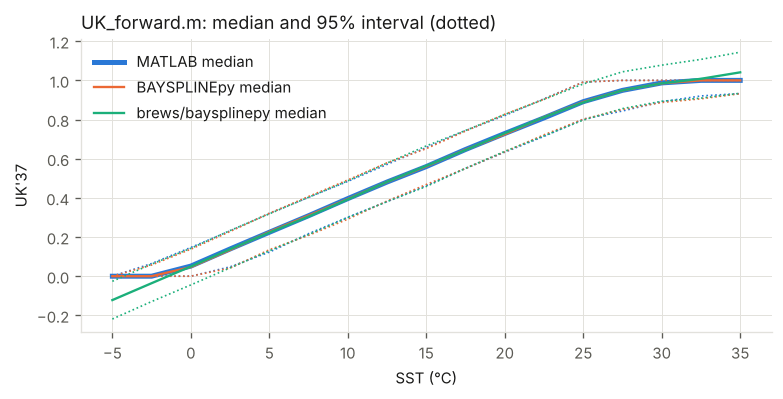

median UK'37, BAYSPLINEpy - MATLAB, max over SSTs: 0.0050
checkSeasonality: 13 locations (incl. edges, vertices, dateline), identical to MATLAB: True


In [9]:
p = ours.load_posterior()
spl = ours.Spline(p.knots)
if HAVE_REF:
    x = np.atleast_1d(ref["spline_x"]).astype(float)
    print(f"spline vs reference fnval, max |diff| over 1000 draws x {x.size} SSTs: "
          f"{np.abs(spl(x, p.bdraws) - ref['spline_mean']).max():.1e}")
if HAVE_BREWS:
    from bayspline.utils import extrapolate_spline, augknt
    xx = np.linspace(-30, 60, 901)
    worst = max(np.abs(spl(xx, c) - extrapolate_spline([augknt(p.knots, 2), c, 2])(xx)).max()
                for c in p.bdraws)
    print(f"spline vs brews' fnxtr port, max |diff| over 1000 draws, -30..60 °C: {worst:.1e}")

ssts = np.arange(-5, 35.1, 2.5)
fwd = ours.uk_forward(ssts, seed=SEED)
fig, ax = plt.subplots(figsize=(6.6, 3.4))
def band(name, e, ls="-"):
    q = np.percentile(e, [2.5, 50, 97.5], axis=1)
    ax.plot(ssts, q[1], ls=ls, color=COLORS.get(name, COLORS["brews/baysplinepy"]),
            lw=3 if name == "MATLAB" else 1.4, label=f"{name} median")
    ax.plot(ssts, q[2], ls=":", color=COLORS.get(name, COLORS["brews/baysplinepy"]), lw=1)
    ax.plot(ssts, q[0], ls=":", color=COLORS.get(name, COLORS["brews/baysplinepy"]), lw=1)
    return q
if HAVE_REF:
    qm = band("MATLAB", np.atleast_2d(ref["forward"]))
qo = band("BAYSPLINEpy", fwd.uk)
if HAVE_BREWS:
    np.random.seed(SEED)
    qb = band("brews/baysplinepy", brews.predict_uk(ssts).ensemble)
    print(f"brews' forward draws above 1 (not clipped, unlike MATLAB): "
          f"{(brews.predict_uk(ssts).ensemble > 1).mean():.1%}")
ax.set_xlabel("SST (°C)"); ax.set_ylabel("UK'37")
ax.set_title("UK_forward.m: median and 95% interval (dotted)", loc="left")
ax.legend(); fig.tight_layout(); plt.show()
if HAVE_REF:
    print(f"median UK'37, BAYSPLINEpy - MATLAB, max over SSTs: {np.abs(qo[1] - qm[1]).max():.4f}")

if HAVE_REF:
    months = ours.check_seasonality(ref["season_lat"], ref["season_lon"])
    mask = np.zeros((len(months), 12), bool)
    for k, m in enumerate(months):
        mask[k, m - 1] = True
    print(f"checkSeasonality: {len(months)} locations (incl. edges, vertices, dateline), "
          f"identical to MATLAB: {np.array_equal(mask, np.atleast_2d(ref['season_months']).astype(bool))}")

## 7. Speed, and using every CPU

MATLAB's `parfor` spreads the 500 chains over a worker pool; BAYSPLINEpy does the same with
`n_jobs` (default: every CPU this process may use). The chains are cut into 50 fixed blocks with
their own random streams, so **the answer does not depend on the number of CPUs** — checked below
bit for bit.

DemoScript record, N = 97, 500 chains x 500 iterations
  BAYSPLINEpy n_jobs=1     3.65 s   speed-up x1.0
  BAYSPLINEpy n_jobs=2     1.67 s   speed-up x2.2
  BAYSPLINEpy n_jobs=4     1.46 s   speed-up x2.5
  identical output for every n_jobs: True
  brews/baysplinepy         14.15 s   (one core; x10 slower than all-CPU BAYSPLINEpy)
  reference run            250.80 s   (Octave 8.4.0; parfor runs serially in Octave)


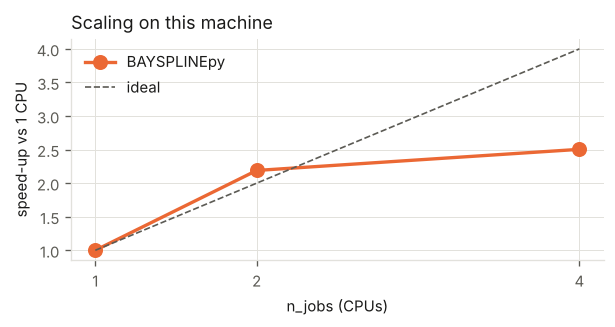

In [10]:
def timed(fn, *a, **k):
    t0, c0 = time.perf_counter(), time.process_time()
    r = fn(*a, **k)
    return r, time.perf_counter() - t0

n_cpu = ours.available_cpus()
jobs = sorted({1, 2, max(1, n_cpu // 2), n_cpu})
walls, results = {}, {}
for j in jobs:
    results[j], walls[j] = timed(ours.uk_predict, uk, PSTD, seed=SEED, n_jobs=j)
same = all(np.array_equal(results[jobs[0]].sst, r.sst) and
           np.array_equal(results[jobs[0]].ensemble, r.ensemble) for r in results.values())
print(f"DemoScript record, N = {uk.size}, 500 chains x 500 iterations")
for j in jobs:
    print(f"  BAYSPLINEpy n_jobs={j:<3d} {walls[j]:6.2f} s   speed-up x{walls[1] / walls[j]:.1f}")
print(f"  identical output for every n_jobs: {same}")
if HAVE_BREWS:
    print(f"  brews/baysplinepy        {t_brews:6.2f} s   (one core; x{t_brews / walls[n_cpu]:.0f} slower than all-CPU BAYSPLINEpy)")
if HAVE_REF:
    print(f"  reference run            {float(ref['provenance'].demo_seconds):6.2f} s   ({ref['provenance'].engine}; parfor runs serially in Octave)")

fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.plot(jobs, [walls[1] / walls[j] for j in jobs], marker="o", ms=8, lw=2, color=COLORS["BAYSPLINEpy"],
        label="BAYSPLINEpy")
ax.plot(jobs, jobs, ls="--", lw=1, color=MUTED, label="ideal")
ax.set_xlabel("n_jobs (CPUs)"); ax.set_ylabel("speed-up vs 1 CPU")
ax.set_xticks(jobs)
ax.set_title("Scaling on this machine", loc="left"); ax.legend()
fig.tight_layout(); plt.show()

## Summary

- **Deterministic quantities agree exactly** with the reference: prior means, jump width, the spline
  (to 1e-15, against both the reference and Brewster's independent `fnxtr` port), and
  `checkSeasonality` including edges, vertices and the dateline.
- **The SST percentiles agree within sampling noise** — MATLAB's run falls inside BAYSPLINEpy's
  seed-to-seed spread with no offset (§4); acceptance and R-hat likewise.
- **`brews/baysplinepy` as shipped runs warm and wide on high-UK'37 records**: on the Gulf of Aden
  demo its median is ~0.4 °C high and its 97.5th percentile ~3 °C high. The cause is one line —
  `sample_now = initial_sst` aliases the prior mean — and fixing it alone brings his port into
  agreement (§2). At UK'37 0.4–0.6 the effect vanishes, which is why his tests pass.
- **`output.ens` comes from four of the 500 chains** in MATLAB (§5). Reproduced by default;
  `ens="spread"` is offered. Jess's call.
- **Speed**: BAYSPLINEpy uses every CPU with results independent of the CPU count (§7).

For the line-by-line account, see `docs/BAYSPLINEpy/PORTING.md`.